<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/statistical_field_theory/sft_ch03_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Statistical Field Theory* — `sft_ch03_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# SFT Ch 3 Figures — Colab Notebook
**Statistical Field Theory · Chapter 3: The Renormalisation Group**

PSE Lab · SeoulTech · Tong (Cambridge)

Figures saved to `figures/ch03/`. Run each cell independently.

| Figure | Topic | Slide |
|--------|-------|-------|
| fig01 | RG idea: block spins, $\beta(g)$, universality | §3.1 |
| fig02 | RG flow $(t,g)$ + relevant/irrelevant/marginal | §3.1–3.2 |
| fig03 | Gaussian FP, $\xi(t)$, dangerously irrelevant | §3.3 |
| fig04 | $\epsilon$-expansion: $\nu$, $\gamma$, Rushbrooke | §3.5 |
| fig05 | Running coupling + $O(N)$ exponents | §3.4–3.5 |

---
## fig01 · RG Idea (§3.1)

**Left**: Kadanoff block spin coarse-graining ($b=2$). **Centre**: Beta function $\beta(g)=\epsilon g-Cg^2$ — Gaussian and Wilson-Fisher fixed points. **Right**: Universality — different systems flow to the same RG fixed point.

  saved -> figures/ch03/fig01_rg_idea.png


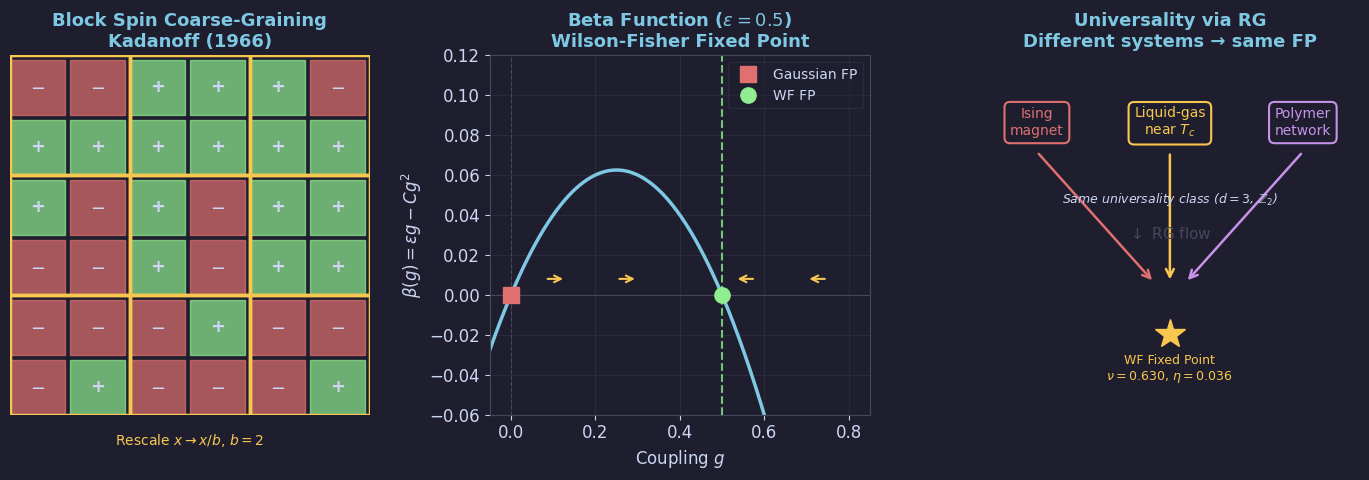

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch03'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig01: RG idea — block spins, beta fn, universality (Ch 3.1) ──────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Panel 1: block spin schematic
ax = axes[0]
ax.set_xlim(0,6); ax.set_ylim(0,6); ax.set_aspect('equal'); ax.axis('off')
ax.set_title('Block Spin Coarse-Graining\nKadanoff (1966)', color=BLUE)
np.random.seed(42)
spins = np.random.choice([-1,1], size=(6,6))
for i in range(6):
    for j in range(6):
        c = GREEN if spins[i,j]==1 else RED
        ax.add_patch(plt.Rectangle((j,i),0.92,0.92, color=c, alpha=0.7))
        ax.text(j+0.46, i+0.46, '+' if spins[i,j]==1 else r'$-$',
                ha='center', va='center', fontsize=13, color=FG, fontweight='bold')
for bi in range(3):
    for bj in range(3):
        ax.add_patch(plt.Rectangle((bj*2,bi*2),2,2,
                     fill=False, edgecolor=YELLOW, lw=2.5))
ax.text(3.0,-0.5, r'Rescale $x\to x/b$, $b=2$',
        ha='center', color=YELLOW, fontsize=10)

# Panel 2: beta function
ax2 = axes[1]
g = np.linspace(-0.05, 0.8, 400)
eps_v, C_v = 0.5, 1.0
beta = eps_v*g - C_v*g**2
g_star = eps_v/C_v
ax2.plot(g, beta, color=BLUE, lw=2.5)
ax2.axhline(0, color=EDGE, lw=0.8)
ax2.axvline(0, color=EDGE, lw=0.8, ls='--')
ax2.axvline(g_star, color=GREEN, lw=1.5, ls='--', alpha=0.8)
ax2.plot([0],[0], 's', color=RED, ms=11, zorder=5, label='Gaussian FP')
ax2.plot([g_star],[0], 'o', color=GREEN, ms=11, zorder=5, label='WF FP')
for g0, dx in [(0.08,0.05),(0.25,0.05),(0.58,-0.05),(0.75,-0.05)]:
    ax2.annotate('', xy=(g0+dx,0.008), xytext=(g0,0.008),
                arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.5, mutation_scale=12))
ax2.set_xlabel('Coupling $g$')
ax2.set_ylabel(r'$\beta(g)=\epsilon g - Cg^2$')
ax2.set_title(r'Beta Function ($\epsilon=0.5$)'+'\nWilson-Fisher Fixed Point', color=BLUE)
ax2.legend(fontsize=10, labelcolor=FG); ax2.grid(True)
ax2.set_xlim(-0.05,0.85); ax2.set_ylim(-0.06,0.12)

# Panel 3: universality schematic
ax3 = axes[2]
ax3.set_xlim(0,10); ax3.set_ylim(0,8); ax3.axis('off')
ax3.set_title('Universality via RG\nDifferent systems → same FP', color=BLUE)
systems = [(1.5,6.5,'Ising\nmagnet',RED),
           (5.0,6.5,'Liquid-gas\nnear $T_c$',YELLOW),
           (8.5,6.5,'Polymer\nnetwork',PURPLE)]
fp_x, fp_y = 5.0, 1.8
for sx, sy, name, col in systems:
    ax3.text(sx, sy, name, ha='center', va='center', fontsize=10, color=col,
             bbox=dict(boxstyle='round,pad=0.4', fc=BG, ec=col, lw=1.5))
    ax3.annotate('', xy=(fp_x+(sx-fp_x)*0.12, fp_y+(sy-fp_y)*0.18+0.3),
                xytext=(sx, sy-0.65),
                arrowprops=dict(arrowstyle='->', color=col, lw=1.8,
                                mutation_scale=14,
                                connectionstyle='arc3,rad=0.0'))
ax3.plot(fp_x, fp_y, '*', color=YELLOW, ms=22, zorder=5)
ax3.text(fp_x, fp_y-0.8, 'WF Fixed Point\n'+r'$\nu=0.630,\,\eta=0.036$',
         ha='center', va='center', fontsize=9, color=YELLOW)
ax3.text(5.0, 3.9, r'$\downarrow$ RG flow', ha='center', color=EDGE, fontsize=11)
ax3.text(5.0, 4.7, r'Same universality class ($d=3$, $\mathbb{Z}_2$)',
         ha='center', color=FG, fontsize=9, style='italic')

plt.tight_layout(pad=1.2)
save('fig01_rg_idea.png', fig)


---
## fig02 · RG Flow (§3.1–3.2)

**Left**: Flow in $(t,g)$ space — critical surface separates ordered/disordered phases. **Right**: Coupling classification — relevant grows, irrelevant shrinks, marginal stays.

  saved -> figures/ch03/fig02_rg_flow.png


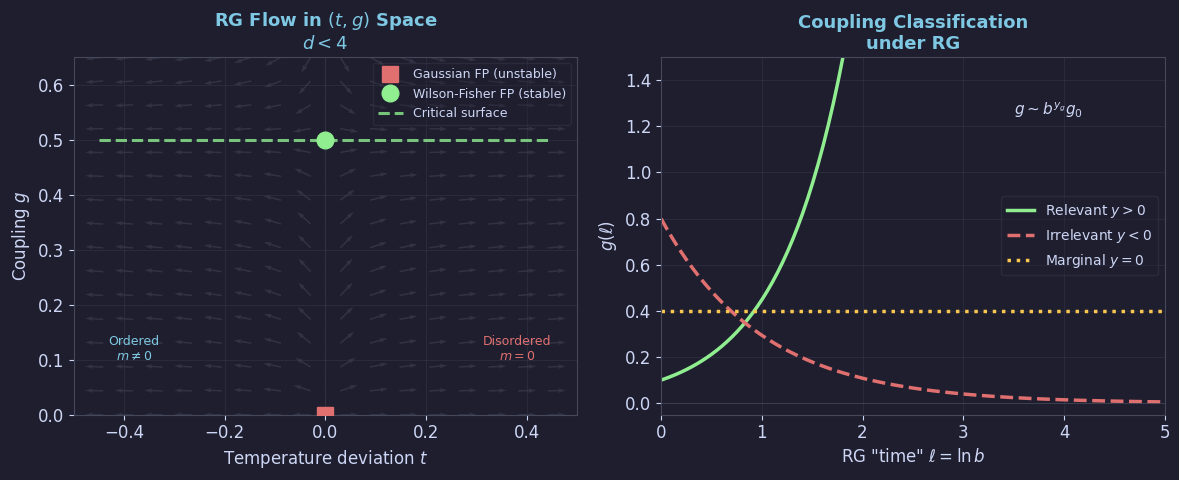

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch03'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig02: RG flow (t,g) + relevant/irrelevant (Ch 3.1–3.2) ──────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(BG)

ax = axes[0]
t_g = np.linspace(-0.5,0.5,18); g_g = np.linspace(0.0,0.65,16)
T_G, G_G = np.meshgrid(t_g, g_g)
dt = 2.0*T_G; dg = 0.5*G_G - G_G**2
mag = np.sqrt(dt**2+dg**2)+1e-10
ax.quiver(T_G, G_G, dt/mag, dg/mag, color=EDGE, alpha=0.5, scale=28, width=0.003)
ax.plot([0],[0], 's', color=RED, ms=12, zorder=5, label='Gaussian FP (unstable)')
ax.plot([0],[0.5], 'o', color=GREEN, ms=12, zorder=5, label='Wilson-Fisher FP (stable)')
t_cs = np.linspace(-0.45,0.45,100)
ax.plot(t_cs, 0.5*np.ones_like(t_cs), color=GREEN, lw=2.2, ls='--',
        alpha=0.8, label='Critical surface')
ax.text(-0.38,0.1,'Ordered\n'+r'$m\neq0$', color=BLUE, fontsize=9, ha='center')
ax.text( 0.38,0.1,'Disordered\n$m=0$', color=RED, fontsize=9, ha='center')
ax.axvline(0, color=EDGE, lw=0.5, ls=':')
ax.set_xlabel('Temperature deviation $t$'); ax.set_ylabel('Coupling $g$')
ax.set_title(r'RG Flow in $(t,g)$ Space'+'\n$d<4$', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG, loc='upper right')
ax.set_xlim(-0.5,0.5); ax.set_ylim(0,0.65); ax.grid(True)

ax2 = axes[1]
ell = np.linspace(0,5,200)
for y, col, lab, ls in [(1.5,GREEN,'Relevant $y>0$','-'),
                         (-1.0,RED,'Irrelevant $y<0$','--'),
                         (0.0,YELLOW,'Marginal $y=0$',':')]:
    g_ell = (0.1*np.exp(y*ell) if y>0 else
             0.8*np.exp(y*ell) if y<0 else
             0.4*np.ones_like(ell))
    ax2.plot(ell, g_ell, color=col, lw=2.5, ls=ls, label=lab)
ax2.axhline(0, color=EDGE, lw=0.5)
ax2.set_xlabel(r'RG "time" $\ell=\ln b$'); ax2.set_ylabel(r'$g(\ell)$')
ax2.set_title('Coupling Classification\nunder RG', color=BLUE)
ax2.legend(fontsize=10, labelcolor=FG); ax2.grid(True)
ax2.set_xlim(0,5); ax2.set_ylim(-0.05,1.5)
ax2.text(3.5,1.25,r'$g\sim b^{y_g}g_0$', color=FG, fontsize=11)

plt.tight_layout(pad=1.2)
save('fig02_rg_flow.png', fig)


---
## fig03 · Gaussian FP & Dangerously Irrelevant (§3.3)

**Left**: Fixed point landscape in coupling space. **Centre**: $\xi\sim t^{-\nu}$ for MFT, 3D Ising, 3D XY. **Right**: Dangerously irrelevant operator — $g_4\to0$ but $g_4/t^\phi$ remains.

  saved -> figures/ch03/fig03_gaussian_fp.png


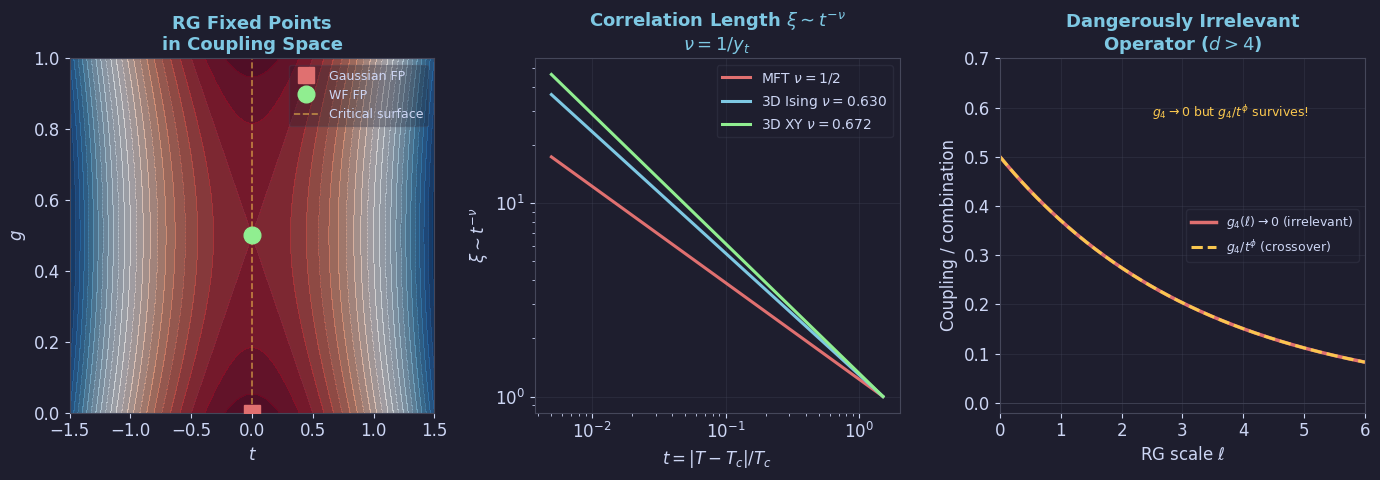

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch03'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig03: Gaussian FP + scaling + dangerously irrelevant (Ch 3.3) ────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)

# Panel 1: FP landscape
ax = axes[0]
t_arr = np.linspace(-1.5,1.5,200); g_arr = np.linspace(0,1.0,200)
T2, G2 = np.meshgrid(t_arr, g_arr)
V = -0.5*T2**2 + 0.5*(G2-0.5)**2
ax.contourf(T2, G2, V, levels=30, cmap='RdBu_r', alpha=0.6)
ax.contour(T2, G2, V, levels=10, colors=EDGE, linewidths=0.5, alpha=0.4)
ax.plot([0],[0], 's', color=RED, ms=12, zorder=5, label='Gaussian FP')
ax.plot([0],[0.5], 'o', color=GREEN, ms=12, zorder=5, label='WF FP')
ax.axvline(0, color=YELLOW, lw=1.2, ls='--', alpha=0.6, label='Critical surface')
ax.set_xlabel('$t$'); ax.set_ylabel('$g$')
ax.set_title('RG Fixed Points\nin Coupling Space', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.set_xlim(-1.5,1.5); ax.set_ylim(0,1)

# Panel 2: xi(T) for various classes
ax2 = axes[1]
t_pos = np.linspace(0.005,1.5,300)
for nu, col, lab in [(0.5,RED,r'MFT $\nu=1/2$'),
                      (0.630,BLUE,r'3D Ising $\nu=0.630$'),
                      (0.672,GREEN,r'3D XY $\nu=0.672$')]:
    xi = t_pos**(-nu); xi /= xi[-1]
    ax2.loglog(t_pos, xi, color=col, lw=2.2, label=lab)
ax2.set_xlabel(r'$t=|T-T_c|/T_c$'); ax2.set_ylabel(r'$\xi\sim t^{-\nu}$')
ax2.set_title(r'Correlation Length $\xi\sim t^{-\nu}$'+'\n'+r'$\nu=1/y_t$', color=BLUE)
ax2.legend(fontsize=10, labelcolor=FG); ax2.grid(True)

# Panel 3: dangerously irrelevant
ax3 = axes[2]
ell3 = np.linspace(0,6,200)
g4 = 0.5*np.exp(-0.3*ell3)
t_val = 0.3; phi = 0.5
h_eff = g4*t_val**(-phi); h_eff_norm = h_eff/h_eff[0]*0.5
ax3.plot(ell3, g4, color=RED, lw=2.5, label=r'$g_4(\ell)\to0$ (irrelevant)')
ax3.plot(ell3, h_eff_norm, color=YELLOW, lw=2.2, ls='--',
         label=r'$g_4/t^\phi$ (crossover)')
ax3.axhline(0, color=EDGE, lw=0.5)
ax3.set_xlabel(r'RG scale $\ell$'); ax3.set_ylabel('Coupling / combination')
ax3.set_title('Dangerously Irrelevant\nOperator ($d>4$)', color=BLUE)
ax3.legend(fontsize=9, labelcolor=FG); ax3.grid(True)
ax3.set_xlim(0,6); ax3.set_ylim(-0.02,0.7)
ax3.text(2.5,0.58,r'$g_4\to0$ but $g_4/t^\phi$ survives!',
         color=YELLOW, fontsize=9)

plt.tight_layout(pad=1.2)
save('fig03_gaussian_fp.png', fig)


---
## fig04 · $\epsilon$-Expansion (§3.5)

**Left**: $\nu(d)$ — $\epsilon$-expansion vs exact 3D value. **Centre**: $\gamma(d)$. **Right**: Rushbrooke relation $\alpha+2\beta+\gamma=2$ verified exactly at all $d$.

  saved -> figures/ch03/fig04_epsilon_exp.png


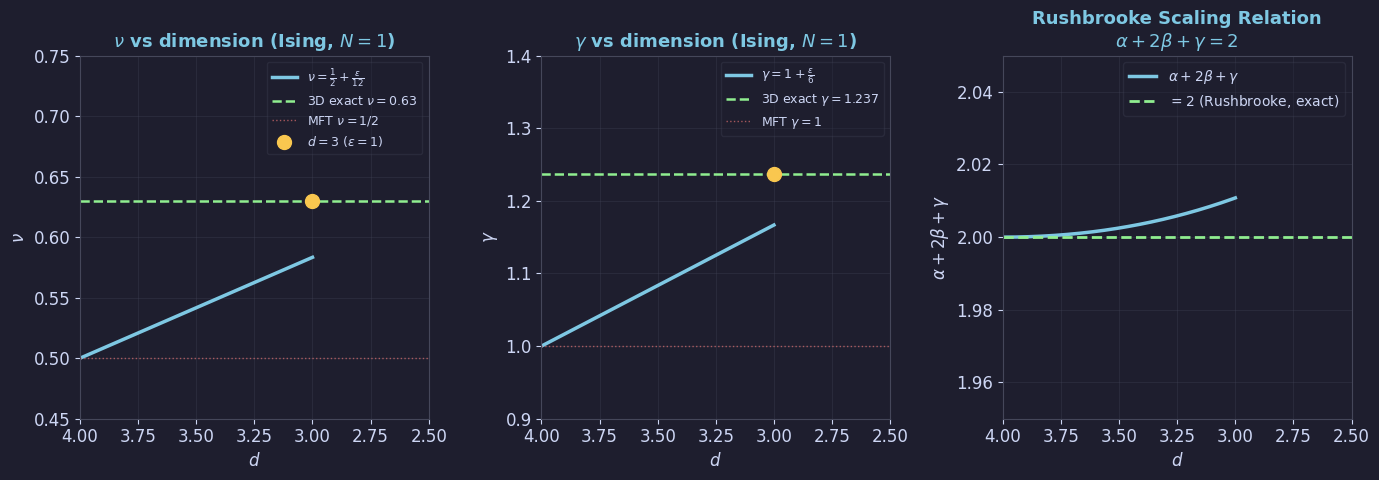

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch03'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig04: ε-expansion: nu, gamma, Rushbrooke (Ch 3.5) ───────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 5))
fig.patch.set_facecolor(BG)
eps = np.linspace(0,1.0,200); d = 4-eps
nu_eps = 0.5 + eps/12
gamma_eps = 1 + eps/6
eta_eps = eps**2/54
alpha_eps = 2 - d*nu_eps
beta_eps = nu_eps*(d-2+eta_eps)/2

nu_3d, gamma_3d = 0.630, 1.237

ax = axes[0]
ax.plot(d, nu_eps, color=BLUE, lw=2.5, label=r'$\nu=\frac{1}{2}+\frac{\epsilon}{12}$')
ax.axhline(nu_3d, color=GREEN, lw=1.8, ls='--', label=f'3D exact $\\nu={nu_3d}$')
ax.axhline(0.5, color=RED, lw=1.0, ls=':', alpha=0.7, label='MFT $\\nu=1/2$')
ax.plot([3],[nu_3d],'o',color=YELLOW,ms=10,zorder=5,label='$d=3$ ($\\epsilon=1$)')
ax.set_xlabel('$d$'); ax.set_ylabel(r'$\nu$')
ax.set_title(r'$\nu$ vs dimension (Ising, $N=1$)', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)
ax.set_xlim(2.5,4.0); ax.set_ylim(0.45,0.75); ax.invert_xaxis()

ax2 = axes[1]
ax2.plot(d, gamma_eps, color=BLUE, lw=2.5, label=r'$\gamma=1+\frac{\epsilon}{6}$')
ax2.axhline(gamma_3d, color=GREEN, lw=1.8, ls='--', label=f'3D exact $\\gamma={gamma_3d}$')
ax2.axhline(1.0, color=RED, lw=1.0, ls=':', alpha=0.7, label='MFT $\\gamma=1$')
ax2.plot([3],[gamma_3d],'o',color=YELLOW,ms=10,zorder=5)
ax2.set_xlabel('$d$'); ax2.set_ylabel(r'$\gamma$')
ax2.set_title(r'$\gamma$ vs dimension (Ising, $N=1$)', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True)
ax2.set_xlim(2.5,4.0); ax2.set_ylim(0.9,1.4); ax2.invert_xaxis()

ax3 = axes[2]
rushbrooke = alpha_eps + 2*beta_eps + gamma_eps
ax3.plot(d, rushbrooke, color=BLUE, lw=2.5, label=r'$\alpha+2\beta+\gamma$')
ax3.axhline(2.0, color=GREEN, lw=2.0, ls='--', label='$=2$ (Rushbrooke, exact)')
ax3.set_xlabel('$d$'); ax3.set_ylabel(r'$\alpha+2\beta+\gamma$')
ax3.set_title('Rushbrooke Scaling Relation\n'+r'$\alpha+2\beta+\gamma=2$', color=BLUE)
ax3.legend(fontsize=10, labelcolor=FG); ax3.grid(True)
ax3.set_xlim(2.5,4.0); ax3.set_ylim(1.95,2.05); ax3.invert_xaxis()

plt.tight_layout(pad=1.2)
save('fig04_epsilon_exp.png', fig)


---
## fig05 · Wilson-Fisher Results (§3.4–3.5)

**Left**: Running coupling $g(\ell)$ flows to $g^*$ from any initial value — universality. **Right**: $\nu$ for $O(N)$ models at $d=3$ — $\epsilon$-expansion vs exact.

  saved -> figures/ch03/fig05_wf_results.png


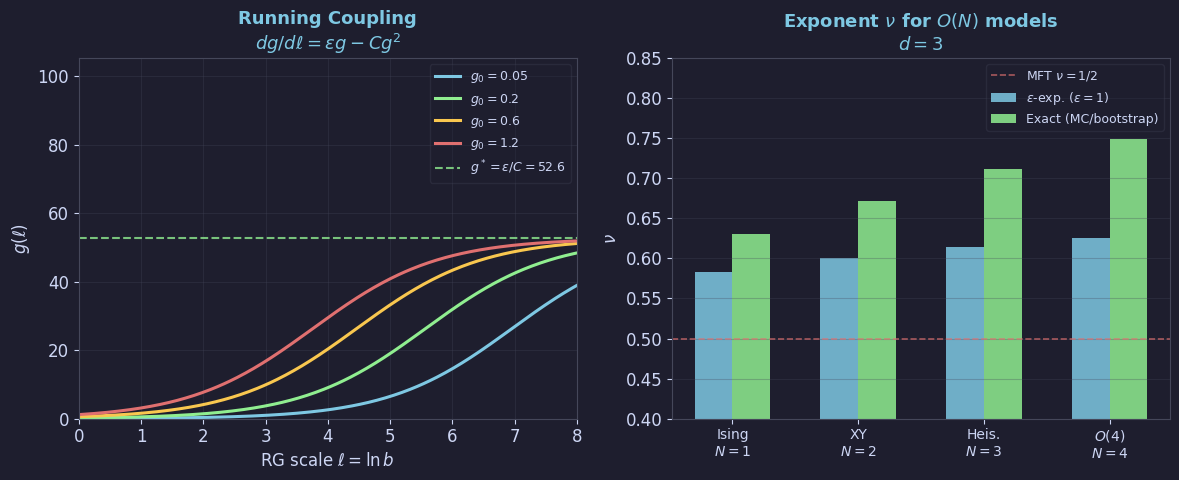

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import os, zipfile

BG='#1e1e2e'; FG='#cdd6f4'; EDGE='#45475a'
BLUE='#7ec8e3'; YELLOW='#f9c74f'; GREEN='#90ee90'
RED='#e07070'; PURPLE='#c792ea'; ORANGE='#ffb347'

plt.rcParams.update({
    'figure.facecolor':BG,'axes.facecolor':BG,'text.color':FG,
    'axes.labelcolor':FG,'xtick.color':FG,'ytick.color':FG,
    'axes.edgecolor':EDGE,'grid.color':EDGE,'grid.alpha':0.3,
    'font.size':12,'axes.titlesize':13,'axes.titleweight':'bold',
    'axes.titlecolor':BLUE,'legend.framealpha':0.3,'legend.edgecolor':EDGE,
})

OUTDIR = 'figures/ch03'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

# ── fig05: Running coupling + O(N) exponents (Ch 3.4–3.5) ─────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.patch.set_facecolor(BG)

# Panel 1: running coupling g(l)
ax = axes[0]
ell = np.linspace(0,8,300)
eps_v = 1.0; C_v = 3/(16*np.pi**2)
g_star_v = eps_v/C_v
for g0, col, lab in [(0.05,BLUE,'$g_0=0.05$'),(0.2,GREEN,'$g_0=0.2$'),
                      (0.6,YELLOW,'$g_0=0.6$'),(1.2,RED,'$g_0=1.2$')]:
    g_l = 1/(np.exp(-eps_v*ell)/g0 + C_v/eps_v*(1-np.exp(-eps_v*ell)))
    ax.plot(ell, np.minimum(g_l, 2.0*g_star_v), color=col, lw=2.2, label=lab)
ax.axhline(g_star_v, color=GREEN, lw=1.5, ls='--', alpha=0.8,
           label=f'$g^*=\\epsilon/C={g_star_v:.1f}$')
ax.set_xlabel(r'RG scale $\ell=\ln b$'); ax.set_ylabel(r'$g(\ell)$')
ax.set_title('Running Coupling\n'+r'$dg/d\ell=\epsilon g - Cg^2$', color=BLUE)
ax.legend(fontsize=9, labelcolor=FG); ax.grid(True)
ax.set_xlim(0,8); ax.set_ylim(0, min(2.0*g_star_v, 300))

# Panel 2: O(N) model exponents bar chart
ax2 = axes[1]
N_arr = np.array([1,2,3,4])
nu_N = 0.5 + (N_arr+2)/(4*(N_arr+8))  # leading order eps=1
nu_exact = np.array([0.630, 0.672, 0.711, 0.749])
nu_labels = ['Ising\n$N=1$','XY\n$N=2$','Heis.\n$N=3$','$O(4)$\n$N=4$']
x = np.arange(len(N_arr)); w = 0.3
ax2.bar(x-w/2, nu_N,     w, color=BLUE,  alpha=0.85, label=r'$\epsilon$-exp. ($\epsilon=1$)')
ax2.bar(x+w/2, nu_exact, w, color=GREEN, alpha=0.85, label='Exact (MC/bootstrap)')
ax2.axhline(0.5, color=RED, lw=1.2, ls='--', alpha=0.7, label='MFT $\\nu=1/2$')
ax2.set_xticks(x); ax2.set_xticklabels(nu_labels, fontsize=10)
ax2.set_ylabel(r'$\nu$')
ax2.set_title(r'Exponent $\nu$ for $O(N)$ models'+'\n$d=3$', color=BLUE)
ax2.legend(fontsize=9, labelcolor=FG); ax2.grid(True, axis='y')
ax2.set_ylim(0.4, 0.85)

plt.tight_layout(pad=1.2)
save('fig05_wf_results.png', fig)


---
## Download All Figures

In [6]:
import os, zipfile
from google.colab import files

OUTDIR = 'figures/ch03'
saved = sorted([f for f in os.listdir(OUTDIR) if f.endswith('.png')]) \
        if os.path.exists(OUTDIR) else []
print(f'Found {len(saved)} figures:')
for f in saved:
    print(f'  {f}  ({os.path.getsize(f"{OUTDIR}/{f}")//1024} KB)')

zip_name = 'sft_ch03_figures.zip'
with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in saved:
        zf.write(f'{OUTDIR}/{fname}', arcname=fname)
print(f'Zip: {zip_name}  ({os.path.getsize(zip_name)//1024} KB)')
files.download(zip_name)


Found 5 figures:
  fig01_rg_idea.png  (166 KB)
  fig02_rg_flow.png  (200 KB)
  fig03_gaussian_fp.png  (285 KB)
  fig04_epsilon_exp.png  (116 KB)
  fig05_wf_results.png  (138 KB)
Zip: sft_ch03_figures.zip  (856 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>